In [1]:
# 导入数据处理和下载工具

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import shutil

# 设置本地数据目录

data_dir = Path(r"D:\AI-Internship\Week02_ML_Practical_Projects\data")
data_dir.mkdir(parents=True, exist_ok=True)

csv_path = data_dir / "creditcard.csv"

# 如果本地没有数据集，则从 Kaggle 下载

if not csv_path.exists():

    dataset_path = Path(
        kagglehub.dataset_download("mlg-ulb/creditcardfraud")
    )

    # 将下载的数据复制到项目目录

    shutil.copy2(
        dataset_path / "creditcard.csv",
        csv_path
    )

    print("数据集下载并保存成功")

else:
    print("检测到本地数据集，跳过下载")

# 读取本地数据集

df = pd.read_csv(csv_path)

# 检查数据集

print("\n数据集路径：", csv_path)
print("数据集形状：", df.shape)

print("\n欺诈类别数量：")
print(df["Class"].value_counts().sort_index())

print("\n欺诈类别比例：")
print(
    (df["Class"].value_counts(normalize=True).sort_index() * 100).round(4)
)

display(df.head())

c:\Users\ROG\miniconda3\envs\ai-intern\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


数据集下载并保存成功

数据集路径： D:\AI-Internship\Week02_ML_Practical_Projects\data\creditcard.csv
数据集形状： (284807, 31)

欺诈类别数量：
Class
0    284315
1       492
Name: count, dtype: int64

欺诈类别比例：
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
# 导入机器学习工具

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

# 检查数据质量

print("缺失值总数：", df.isnull().sum().sum())
print("重复记录数：", df.duplicated().sum())

# 分离特征和目标变量

X = df.drop(columns=["Class"])
y = df["Class"]

# 划分训练集和测试集

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# 只从训练集中提取正常交易

X_normal = X_train.loc[y_train == 0]

# 抽取一万条正常交易用于训练

X_sample = X_normal.sample(
    n=10000,
    random_state=42
)

# 在训练样本上拟合标准化器

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_sample)
X_test_scaled = scaler.transform(X_test)

print("\n训练样本数量：", X_train_scaled.shape)
print("测试样本数量：", X_test_scaled.shape)

print("\n测试集欺诈数量：", y_test.sum())

缺失值总数： 0
重复记录数： 1081

训练样本数量： (10000, 30)
测试样本数量： (56962, 30)

测试集欺诈数量： 98


In [3]:
# 定义两个异常检测模型

models = {
    "Isolation Forest": IsolationForest(
        n_estimators=100,
        contamination=0.01,
        random_state=42,
        n_jobs=-1
    ),

    "One-Class SVM": OneClassSVM(
        kernel="rbf",
        nu=0.01,
        gamma="scale"
    )
}

# 保存模型预测和评价结果

predictions = {}
anomaly_scores = {}
results = []

# 训练和评价模型

for name, model in models.items():

    print(f"\n正在训练：{name}")

    model.fit(X_train_scaled)

    # 预测异常交易

    pred = model.predict(X_test_scaled)

    # 将异常标记转换为 1

    pred = (pred == -1).astype(int)

    # 获取连续异常评分，数值越大越异常

    scores = -model.decision_function(X_test_scaled)

    predictions[name] = pred
    anomaly_scores[name] = scores

    # 计算模型评价指标

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "PR_AUC": average_precision_score(
            y_test, scores
        ),
        "Detected_Anomalies": int(pred.sum())
    })

    print(f"{name} 训练完成")

# 汇总模型比较结果

comparison = pd.DataFrame(results)

display(comparison.round(4))


正在训练：Isolation Forest
Isolation Forest 训练完成

正在训练：One-Class SVM
One-Class SVM 训练完成


,Model,Precision,Recall,F1,PR_AUC,Detected_Anomalies
0,Isolation Forest,0.1026,0.6735,0.1781,0.1502,643
1,One-Class SVM,0.0335,0.8571,0.0644,0.2873,2509


In [4]:
# 保存异常检测模型对比表

comparison.to_csv(
    "../results/anomaly_model_comparison.csv",
    index=False
)

print("异常检测模型对比 CSV 保存成功")

异常检测模型对比 CSV 保存成功


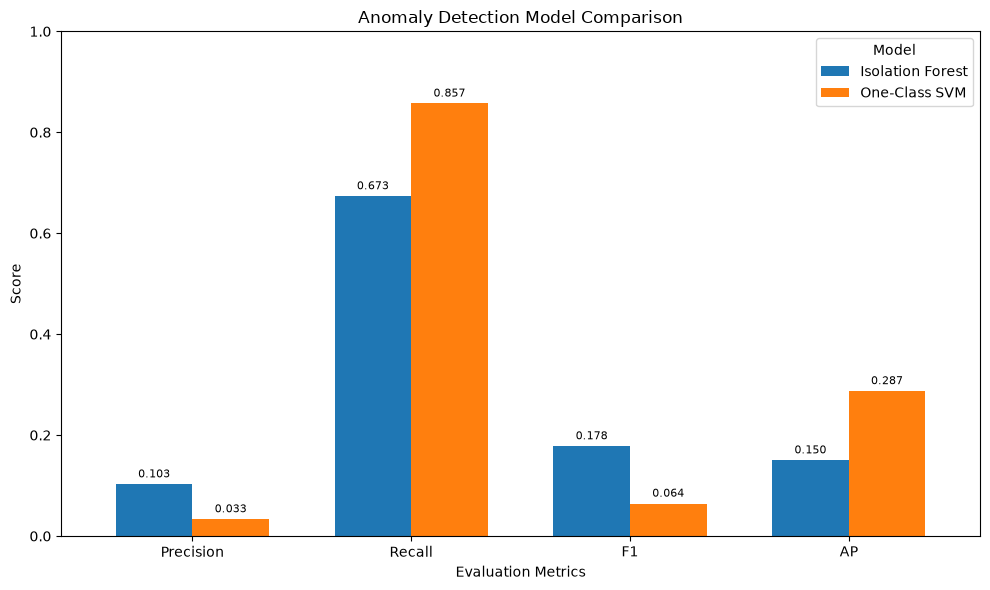

In [5]:
# 绘制两个模型的性能对比图

metrics = [
    "Precision",
    "Recall",
    "F1",
    "PR_AUC"
]

plot_data = comparison.set_index("Model")[metrics].copy()

# 将指标名称改为更准确的 AP

plot_data = plot_data.rename(
    columns={"PR_AUC": "AP"}
)

ax = plot_data.T.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Anomaly Detection Model Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Model")

# 显示柱状图数值

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.tight_layout()

# 保存模型比较图

plt.savefig(
    "../results/figures/anomaly_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

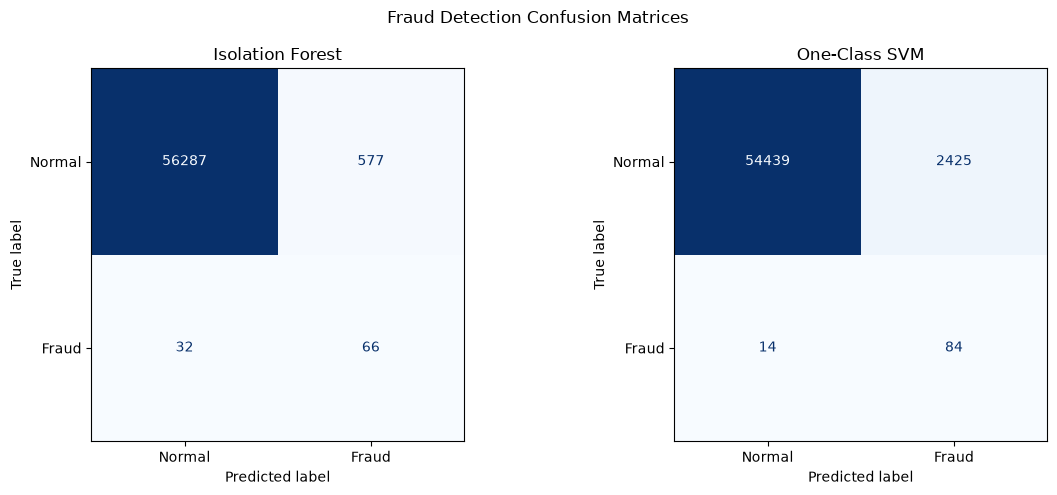

In [6]:
# 导入混淆矩阵工具

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 绘制两个模型的混淆矩阵

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Fraud"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.suptitle("Fraud Detection Confusion Matrices")
plt.tight_layout()

# 保存混淆矩阵图

plt.savefig(
    "../results/figures/anomaly_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

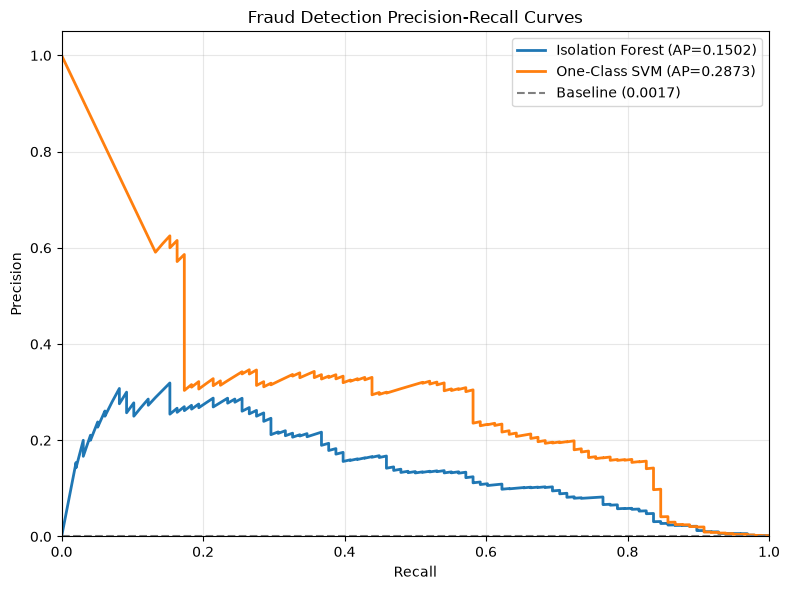

In [7]:
# 导入 PR 曲线评价工具

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

plt.figure(figsize=(8, 6))

# 绘制两个模型的 PR 曲线

for name, scores in anomaly_scores.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        scores
    )

    ap = average_precision_score(
        y_test,
        scores
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP={ap:.4f})"
    )

# 绘制随机排序基准线

baseline = y_test.mean()

plt.axhline(
    y=baseline,
    color="gray",
    linestyle="--",
    label=f"Baseline ({baseline:.4f})"
)

plt.title("Fraud Detection Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# 保存 PR 曲线

plt.savefig(
    "../results/figures/anomaly_pr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# 将平均精度指标统一命名为 AP

comparison = comparison.rename(
    columns={"PR_AUC": "AP"}
)

# 更新模型比较 CSV

comparison.to_csv(
    "../results/anomaly_model_comparison.csv",
    index=False
)

display(comparison.round(4))

print("模型比较表更新成功")

,Model,Precision,Recall,F1,AP,Detected_Anomalies
0,Isolation Forest,0.1026,0.6735,0.1781,0.1502,643
1,One-Class SVM,0.0335,0.8571,0.0644,0.2873,2509


模型比较表更新成功
